In [38]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


## Get Jack's numbers

In [39]:
jackDF = pd.read_csv('../../jacksFiles/B2F_page2_table.csv',index_col=0)
jackDF = jackDF.rename(columns={'mS_GeV':'ms', 'm1_GeV':'m1', 'Delta_m10':'dm','sigma_fb' : 'xsec_fb'})
jackDF = jackDF.drop(columns=['beta_chi1_scalar_rest_frame','N_Run2_plus_3'])

In [40]:
jackDF

,ms,m1,dm,xsec_fb,N_Run2
id,,,,,
100004,450,215.5,60,32.78,1.57
100008,450,204.1,60,74.47,1.53
100006,450,212.4,60,46.63,1.29
100016,600,283.9,60,8.33,1.15
100009,450,204.1,100,71.43,0.98
100007,450,212.4,100,44.91,0.92
100018,600,272.9,60,14.49,0.90
100014,600,288.1,60,5.81,0.76
100005,450,215.5,100,31.51,0.65


### Get B2TF recast data

In [41]:
b2tf_DF = pd.read_csv('../b2tf_effs.csv')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
b2tf_DF['xsec_fb'] = (b2tf_DF['xsec_pb']*1e3)
b2tf_DF['N_Run2'] = b2tf_DF['eff']*b2tf_DF['xsec_fb']*139.0
b2tf_DF['N_Run2_err'] = b2tf_DF['efferror']*b2tf_DF['xsec_fb']*139.0

In [42]:
b2tf_DF['ms'].unique(),b2tf_DF['ctau'].unique()

(array([ 400.,  450.,  600.,  800., 1000.]), array([20.]))

### Add ratio to Jack's Numbers

In [43]:
# Round the keys before matching: dm = m1 - m0 has floating-point noise,
# and Jack's masses are given to 1 decimal place
keys = ['ms', 'm1', 'dm']
jack_keyed = jackDF[keys + ['xsec_fb', 'N_Run2']].copy()
jack_keyed[keys] = jack_keyed[keys].round(1)

b2tf_keyed = b2tf_DF.copy()
b2tf_keyed[keys] = b2tf_keyed[keys].round(1)

merged = b2tf_keyed.merge(jack_keyed, on=keys, how='left',
                          suffixes=('', '_jack'), validate='many_to_one')

b2tf_DF['N_Run2_jack'] = merged['N_Run2_jack'].values
b2tf_DF['xsec_jack'] = merged['xsec_fb_jack'].values
b2tf_DF['N_Run2_ratio'] = b2tf_DF['N_Run2'] / b2tf_DF['N_Run2_jack']
b2tf_DF['N_Run2_ratio_err'] = b2tf_DF['N_Run2_err'] / b2tf_DF['N_Run2_jack']



In [44]:
b2tf_match = b2tf_DF[b2tf_DF['N_Run2_ratio'].notnull()]
b2tf_match = b2tf_match.sort_values(by=['N_Run2_jack'], ascending=False)
# b2tf_match[['ms', 'm1', 'dm', 'N_Run2', 'N_Run2_err', 'N_Run2_jack', 'N_Run2_ratio', 'N_Run2_ratio_err']]
b2tf_match[['ms', 'm1', 'dm', 'N_Run2', 'N_Run2_jack', 'N_Run2_ratio','filename']]

,ms,m1,dm,N_Run2,N_Run2_jack,N_Run2_ratio,filename
14,450.0,215.5,60.0,1.528462,1.57,0.973543,../processFolders/pp2chi1chi2_01j_nosmear/Even...
18,450.0,204.1,60.0,3.272396,1.53,2.138821,../processFolders/pp2chi1chi2_01j_nosmear/Even...
16,450.0,212.4,60.0,2.293243,1.29,1.777708,../processFolders/pp2chi1chi2_01j_nosmear/Even...
19,450.0,204.1,100.0,1.791338,0.98,1.827896,../processFolders/pp2chi1chi2_01j_nosmear/Even...
17,450.0,212.4,100.0,1.403720,0.92,1.525782,../processFolders/pp2chi1chi2_01j_nosmear/Even...
27,600.0,272.9,60.0,2.591761,0.90,2.879734,../processFolders/pp2chi1chi2_01j_nosmear/Even...
24,600.0,288.1,60.0,1.078164,0.76,1.418636,../processFolders/pp2chi1chi2_01j_nosmear/Even...
15,450.0,215.5,100.0,0.987688,0.65,1.519521,../processFolders/pp2chi1chi2_01j_nosmear/Even...
25,600.0,288.1,100.0,1.488918,0.61,2.440850,../processFolders/pp2chi1chi2_01j_nosmear/Even...
22,600.0,291.5,60.0,0.756572,0.58,1.304435,../processFolders/pp2chi1chi2_01j_nosmear/Even...


## Plot Effs

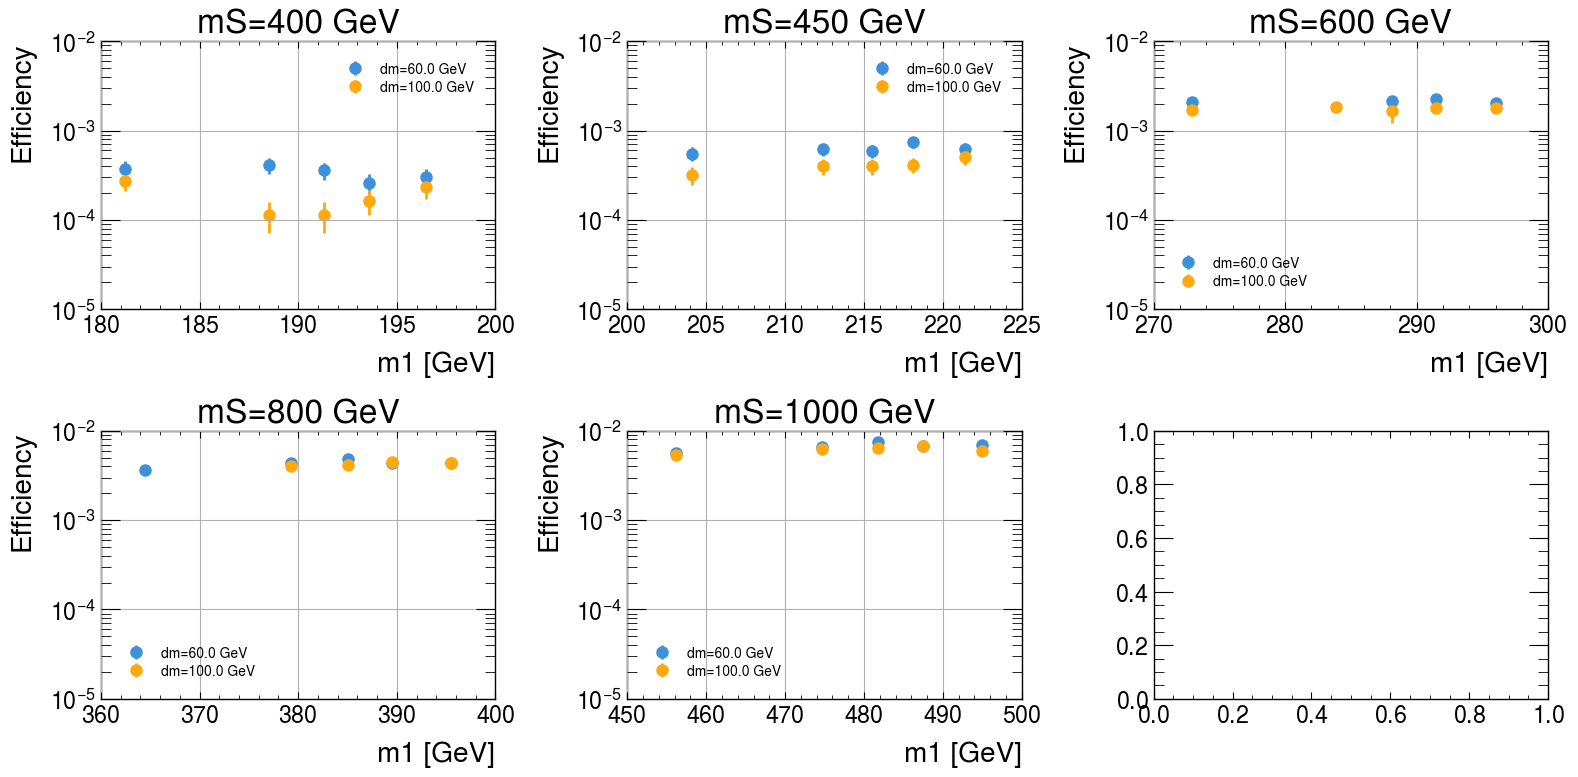

In [48]:
mSValues = b2tf_DF['ms'].unique()
ncolumns = 3
nrows = mSValues.size // ncolumns + (mSValues.size % ncolumns > 0)

fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
for ms in mSValues:
    df = b2tf_DF[b2tf_DF['ms'] == ms]
    for dm,dfB in df.groupby('dm'):
        axes[iax].errorbar(dfB['m1'], dfB['eff'], 
                           yerr=dfB['efferror'], fmt='o', label=f'dm={dm:.1f} GeV')
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel('Efficiency')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-5, 1e-2)
    axes[iax].grid()
    iax += 1
plt.tight_layout()
plt.show()

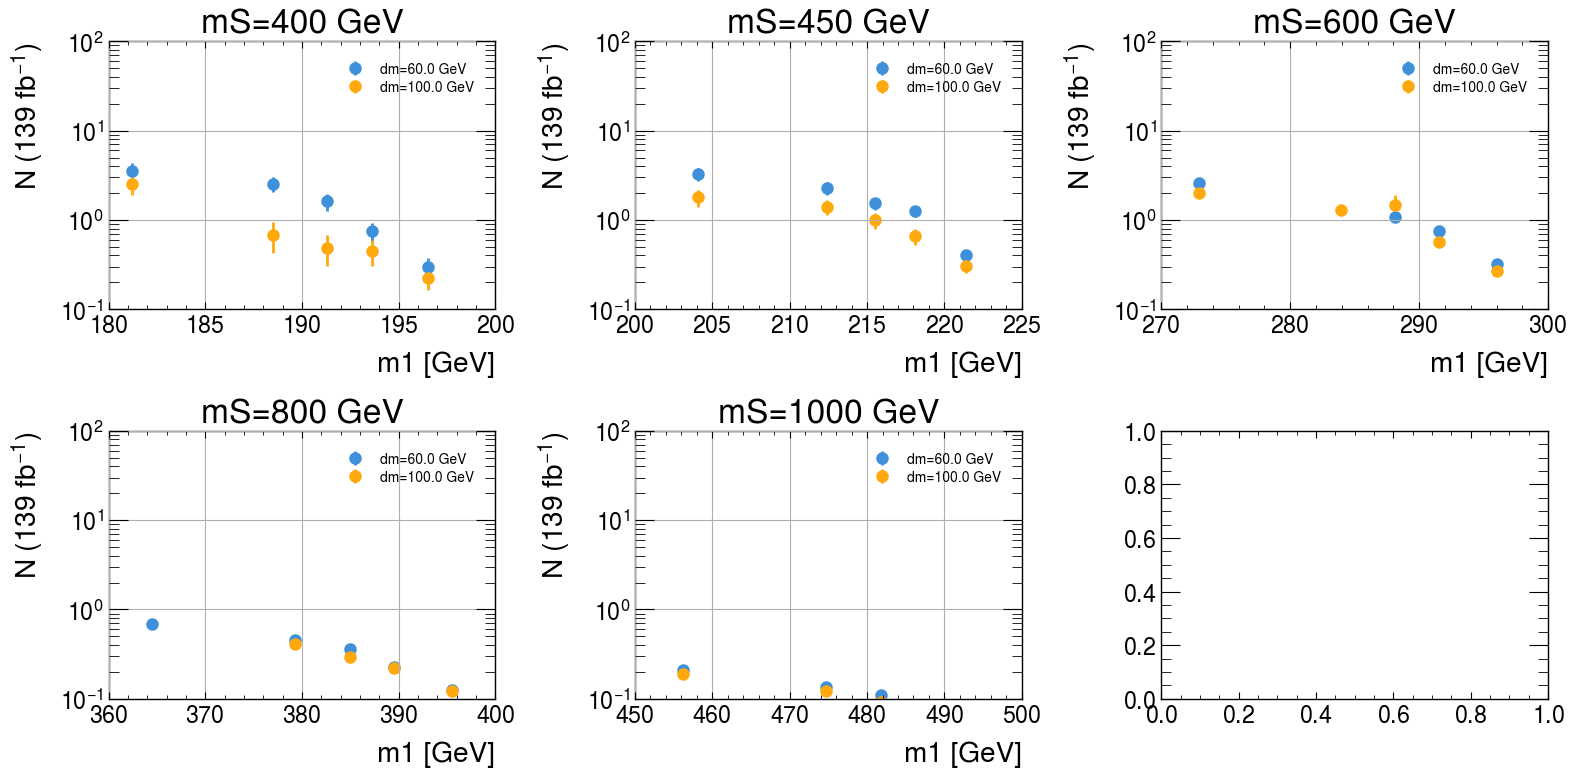

In [52]:
mSValues = b2tf_DF['ms'].unique()
ncolumns = 3
nrows = mSValues.size // ncolumns + (mSValues.size % ncolumns > 0)

fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(16, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]
for ms in mSValues:
    df = b2tf_DF[b2tf_DF['ms'] == ms]
    for dm,dfB in df.groupby('dm'):
        axes[iax].errorbar(dfB['m1'], dfB['N_Run2'], 
                           yerr=dfB['N_Run2_err'], fmt='o', label=f'dm={dm:.1f} GeV')
        
    axes[iax].set_xlabel('m1 [GeV]')
    axes[iax].set_ylabel(r'N (139 fb$^{-1}$)')
    axes[iax].legend(fontsize=10)
    axes[iax].set_title(f'mS={ms:.0f} GeV')
    axes[iax].set_yscale('log')
    axes[iax].set_ylim(1e-1, 1e2)
    axes[iax].grid()
    iax += 1
plt.tight_layout()
plt.show()